# Mappa NLL e densità di probabilità dei tempi

Origine: `~/juno/prova/src/mappa_e_pdf.ipynb`.

Copia organizzata per la consultazione: le celle eseguibili e gli output originali sono conservati. I titoli aggiunti sono celle Markdown; i risultati salvati non sono stati ricalcolati. Eseguire dalla cartella di questo notebook. I dati ROOT esterni e gli eventuali problemi già presenti sono descritti in `docs/DATI_E_PERCORSI.md` nella radice del repository.

Le tabelle necessarie ai grafici sono incluse. Nelle istruzioni originali che seguono, `src` indica questa cartella `mappa_nll`; `../output` indica la cartella dei ROOT di ricostruzione, da fornire separatamente.


# Mappa correttiva NLL e PDF approssimate

Questa cartella contiene il necessario per **calcolare e visualizzare la mappa**:
un solo `fit.cpp`, questo notebook e file di testo. Il calcolo richiede ROOT;
il notebook richiede Python con NumPy, SciPy e Matplotlib.

Il C++ legge `../output/output_*.root`, raggruppati per PMT da `macro2.cpp`.
I dati sono già selezionati su PMT Hamamatsu. Per ciascuno dei 40 anelli in
$\cos\theta$ minimizza un solo spostamento $\delta$ condiviso da tutti gli eventi:

$$-\log L(\delta)=-\sum_{e,i}\log\max\left[p_{k(q_{ei})}
(t^{\rm first}_{ei}-\mathrm{ToF}_i-t_{0,e}-\delta),10^{-9}\right].$$

**`residual_times` contiene già FHT − ToF**, con indice 1,60 e posizione nominale:
nel C++ si sottrae soltanto il `t0` salvato da JVertex. Il ToF non va sottratto
di nuovo. `t0` rimane fisso durante la stima della mappa.

Per accelerare il calcolo si usano conteggi temporali in bin da **0,25 ns**,
conservando tutte le code, e una tabella delle log-PDF a passo **0,025 ns**.
La scansione iniziale cerca il minimo in un intervallo largo; Brent lo affina.
Non è un fit del picco dei tempi: il parametro viene scelto dalla NLL.

## Ricalcolare la mappa

Da un terminale aperto **in questa cartella**:

```bash
g++ -O2 -Wall -Wextra -std=c++17 fit.cpp -o /tmp/fit_mappa $(root-config --cflags --libs)
/tmp/fit_mappa ../output pdf_parameters.txt .
```

L'eseguibile viene lasciato in `/tmp` per mantenere pulita questa cartella.
Il secondo comando riscrive le sei tabelle della mappa dopo aver completato tutte le run.
Per input o output diversi, modificare i tre argomenti. I ROOT originali non vengono modificati.

| File | Contenuto |
|---|---|
| `pdf_parameters.txt` | 10 righe: mu, sigma, tau1, tau2, peso1 |
| `run_z.txt` | numero run e z nominale in mm, ordinati per z |
| `delta_nll.txt` | una riga per run, 40 colonne: spostamenti a t0 fisso, in ns |
| `delta_relative.txt` | stessa matrice dopo sottrazione del riferimento |
| `delta_r.txt` | mappa relativa simmetrizzata: righe in r crescente, 20 colonne con cos(theta)>0 |
| `r.txt` | raggi delle righe di delta_r.txt, in mm |
| `cos_theta.txt` | centri angolari delle colonne di delta_r.txt |

Le matrici sono numeri separati da spazi e si leggono direttamente con `np.loadtxt`.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import exponnorm

cartella = Path.cwd()
assert (cartella / "pdf_parameters.txt").exists(), "Eseguire il notebook dalla cartella src"
parametri = np.loadtxt(cartella / "pdf_parameters.txt")
run_z = np.loadtxt(cartella / "run_z.txt")
delta_nll = np.loadtxt(cartella / "delta_nll.txt")
delta_relativa = np.loadtxt(cartella / "delta_relative.txt")
delta_r = np.loadtxt(cartella / "delta_r.txt")
r = np.loadtxt(cartella / "r.txt")
cos_theta = np.loadtxt(cartella / "cos_theta.txt")

assert parametri.shape == (10, 5)
assert delta_nll.shape == delta_relativa.shape == (len(run_z), 40)
assert delta_r.shape == (len(r), len(cos_theta))
assert all(np.isfinite(a).all() for a in [parametri, run_z, delta_nll, delta_relativa, delta_r, r, cos_theta])
assert np.all(np.diff(r) > 0) and np.all(np.diff(run_z[:, 1]) > 0)
print(f"Run: {len(run_z)}; mappa positiva: {delta_r.shape}")
print(f"Correzione relativa positiva: {delta_r.min():.3f} ... {delta_r.max():.3f} ns")

Run: 39; mappa positiva: (21, 20)
Correzione relativa positiva: -3.513 ... 10.025 ns


## PDF usate nella NLL

Ogni PDF è una miscela **normalizzata a integrale uno** di due distribuzioni
ex-Gaussiane con gli stessi $\mu$ e $\sigma$:

$$p(t)=w\,\mathrm{ExGauss}(t;\mu,\sigma,\tau_1)
      +(1-w)\,\mathrm{ExGauss}(t;\mu,\sigma,\tau_2).$$

Sono stime dall'immagine iniziale, **non le PDF ufficiali di JVertex**.
Solo le curve 1, 2 e 10 pe sono state stimate dalla figura; i parametri da 3 a 9 pe
sono interpolati fra 2 e 10. L'origine temporale della figura è conservata;
le code fuori dalla figura non sono determinate direttamente dai dati dell'immagine.

La classe è `k = min(9, max(0, floor(q) - 1))`: q<2 usa la PDF 1,
2≤q<3 usa la PDF 2, ..., q≥10 usa la PDF 10. Il floor 1e-9 è applicato solo
nel calcolo della log-likelihood; nel grafico mostriamo le PDF senza floor.
La normalizzazione al massimo, nel pannello destro, serve solo al confronto visivo.


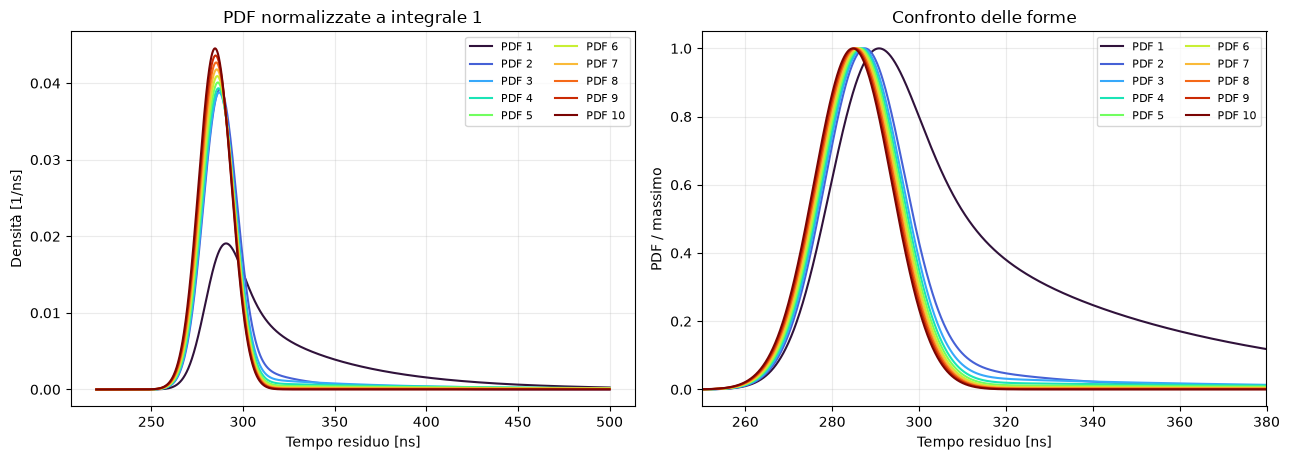

In [2]:
def pdf(t, k):
    mu, sigma, tau1, tau2, peso = parametri[k]
    return (peso * exponnorm.pdf(t, tau1 / sigma, loc=mu, scale=sigma)
            + (1 - peso) * exponnorm.pdf(t, tau2 / sigma, loc=mu, scale=sigma))

t = np.linspace(220, 500, 4000)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
for k in range(10):
    densita = pdf(t, k)
    colore = plt.cm.turbo(k / 9)
    axes[0].plot(t, densita, color=colore, label=f"PDF {k + 1}")
    axes[1].plot(t, densita / densita.max(), color=colore, label=f"PDF {k + 1}")
axes[0].set(xlabel="Tempo residuo [ns]", ylabel="Densità [1/ns]", title="PDF normalizzate a integrale 1")
axes[1].set(xlabel="Tempo residuo [ns]", ylabel="PDF / massimo", title="Confronto delle forme", xlim=(250, 380))
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

## Mappa completa e riferimento

`delta_nll.txt` contiene lo spostamento stimato con il t0 originale fisso.
Per ogni run si fittano anche **insieme gli hit degli anelli 18–21**
($-0.1\leq\cos\theta<0.1$); il loro spostamento è il riferimento:

$$\delta_{\rm relativa}(z,c)=\delta_{\rm NLL}(z,c)-\delta_{\rm riferimento}(z).$$

Non è una semplice media dei quattro spostamenti. La sottrazione fissa l'offset
per confrontare le forme; se t0 rimane fisso, la mappa relativa da sola non
riproduce la stessa NLL della mappa assoluta. Nella seconda ricostruzione t0 è libero.


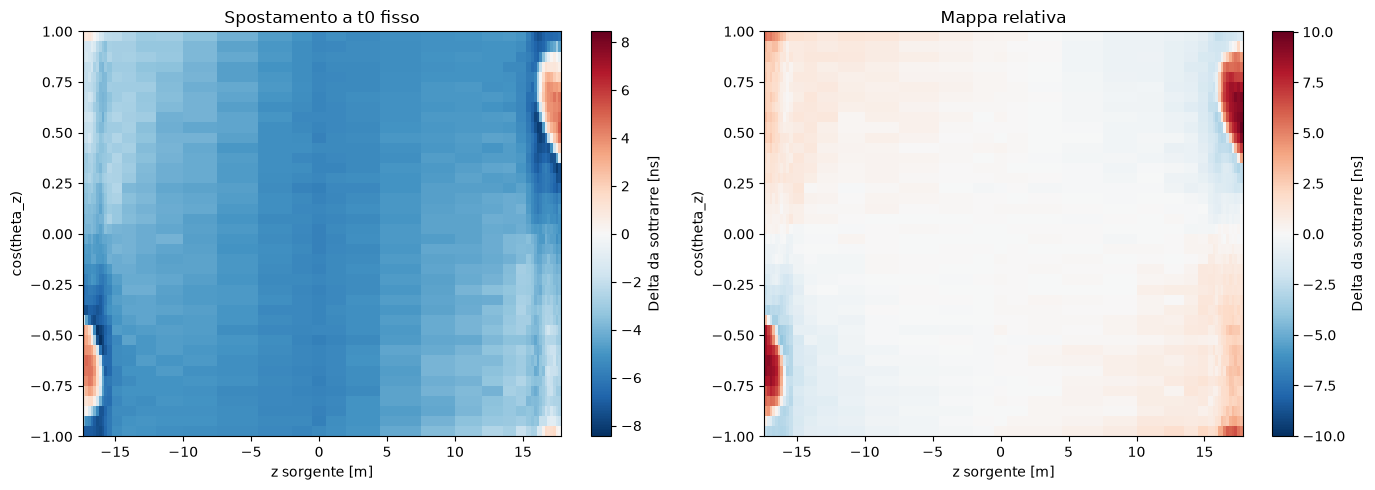

In [3]:
def bordi(centri, minimo=None, massimo=None):
    centri = np.asarray(centri)
    edges = np.r_[centri[0] - (centri[1] - centri[0]) / 2,
                  (centri[:-1] + centri[1:]) / 2,
                  centri[-1] + (centri[-1] - centri[-2]) / 2]
    if minimo is not None:
        edges[0] = minimo
    if massimo is not None:
        edges[-1] = massimo
    return edges

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, dati, titolo in zip(axes, [delta_nll, delta_relativa], ["Spostamento a t0 fisso", "Mappa relativa"]):
    limite = max(np.max(np.abs(dati)), 1e-12)
    im = ax.pcolormesh(bordi(run_z[:, 1]) / 1000, np.linspace(-1, 1, 41), dati.T,
                       cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-limite, vcenter=0, vmax=limite))
    ax.set(xlabel="z sorgente [m]", ylabel="cos(theta_z)", title=titolo)
    fig.colorbar(im, ax=ax, label="Delta da sottrarre [ns]")
fig.tight_layout()
plt.show()

## Mappa relativa nel quadrante positivo

Per r≥0 e c>0 si calcola la **media aritmetica con uguale peso**:

$$\delta_r(r,c)=\frac{\delta_{\rm relativa}(+r,+c)
                         +\delta_{\rm relativa}(-r,-c)}{2}.$$

Quindi un anello a z negativo e cos(theta) negativo contribuisce al corrispondente
anello positivo. Non si scarta semplicemente metà delle run. Se un lato manca,
si conserva quello disponibile (in questi dati: r=17500 e 17700 mm).
La riga r=0 è mediata fra anelli opposti. Non si applicano soglie arbitrarie
in ampiezza o maschere TIR; anche i piccoli valori negativi sono conservati.


Raggi con un solo lato [mm]: [np.float64(17500.0), np.float64(17700.0)]


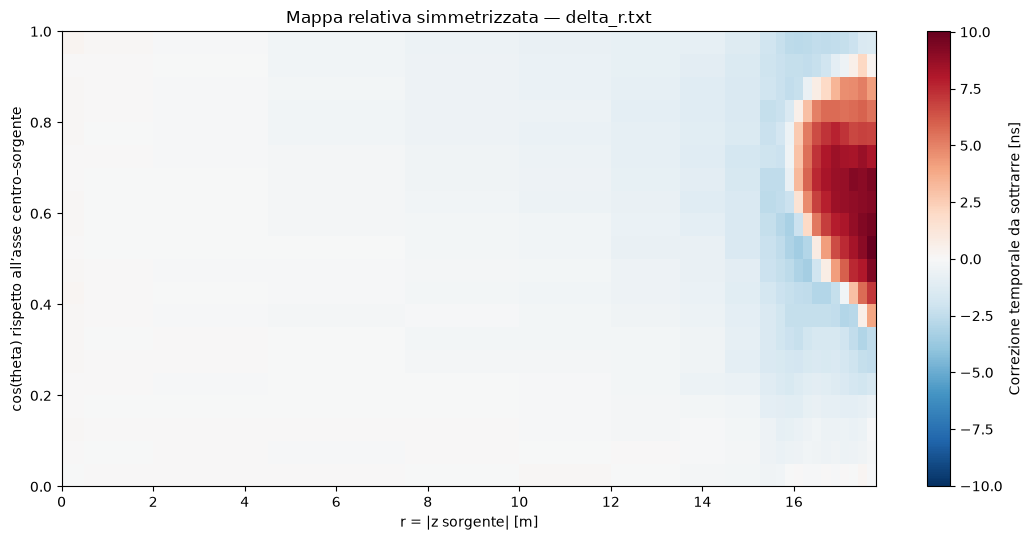

In [4]:
z_disponibili = set(run_z[:, 1])
non_abbinati = [radius for radius in r if radius not in z_disponibili or -radius not in z_disponibili]
print("Raggi con un solo lato [mm]:", non_abbinati)

# Controllo della media simmetrica su tutti i nodi.
per_z = {z: dati for z, dati in zip(run_z[:, 1], delta_relativa)}
for i, radius in enumerate(r):
    lati = []
    if radius in per_z:
        lati.append(per_z[radius][20:])
    if -radius in per_z:
        lati.append(per_z[-radius][:20][::-1])
    np.testing.assert_allclose(delta_r[i], np.mean(lati, axis=0), atol=1e-10, rtol=0)

fig, ax = plt.subplots(figsize=(11, 5.5))
limite = max(np.max(np.abs(delta_r)), 1e-12)
im = ax.pcolormesh(bordi(r, minimo=0) / 1000, bordi(cos_theta, minimo=0, massimo=1), delta_r.T,
                   cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-limite, vcenter=0, vmax=limite))
ax.set(xlabel="r = |z sorgente| [m]", ylabel="cos(theta) rispetto all’asse centro–sorgente",
       title="Mappa relativa simmetrizzata — delta_r.txt", ylim=(0, 1))
fig.colorbar(im, ax=ax, label="Correzione temporale da sottrarre [ns]")
fig.tight_layout()
plt.show()

## Convenzione per usare la mappa nella ricostruzione

Una correzione positiva **si sottrae** ai tempi residui. Nella procedura a due
passaggi già provata, il primo vertice $\mathbf r_1$ seleziona il raggio
$r=|\mathbf r_1|$ e l'angolo di ogni PMT:

$$c_i=\frac{\mathbf r_1\cdot\mathbf r_{\rm PMT,i}}
              {|\mathbf r_1|\,|\mathbf r_{\rm PMT,i}|}.$$

Si interpolano le celle e si tengono **fissi** i delta durante il secondo fit,
con x,y,z,t0 liberi. Per c≤0 la correzione è nulla.
Il codice di applicazione sta fuori da questa cartella: qui si stima la mappa.

La tabella conserva la riga centrale *misurata*. Nell'applicazione precedente
si imponeva invece delta(0,c)=0, con raccordo alla prima riga a 1 m, per evitare
un asse privilegiato al centro. Si usavano inoltre un raccordo da c=0 al primo
centro c=0.025 e l'ultima riga per r>17.7 m. Queste sono scelte di applicazione,
non modifiche alle celle misurate di `delta_r.txt`.

Questa versione essenziale calcola la mappa su tutti gli eventi. Non ripete
lo split pari/dispari della precedente analisi e non costituisce una validazione
indipendente del bias di ricostruzione.
